# Projeto 11 — Agrupando amostras sem usar os rótulos

**SCC02713 · Introdução à Bioinformática**

### Grupo:
- Leonardo Demore - 15674786
- Thiago Tavares  - 15490194
- Julio Fuganti   - 15638792

## 1 - Carregar, reduzir e padronizar os dados

### 1.1 Configuração

Importa as bibliotecas e define os caminhos e as constantes usadas no notebook inteiro. A seed garante que o notebook produza sempre os mesmos resultados.

In [1]:
from pathlib import Path
import tarfile
import urllib.request
import zipfile

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Caminhos
DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
EXPRESSION_FILE = DATA_DIR / "data.csv"
LABELS_FILE = DATA_DIR / "labels.csv"
UCI_URL = "https://archive.ics.uci.edu/static/public/401/gene+expression+cancer+rna+seq.zip"

# Parâmetros da análise
N_GENES = 2000
SEED = 42

DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

### 1.2 Carregamento e pré-processamento

Os dados vêm do repositório da UCI
(<https://archive.ics.uci.edu/dataset/401/gene+expression+cancer+rna+seq>).
O arquivo `.zip` contém um `.tar.gz` com dois CSVs:

- `data.csv`: matriz de expressão (amostras nas linhas, genes nas colunas);
- `labels.csv`: o tipo de tumor de cada amostra.

A função abaixo baixa e extrai os arquivos para `data/` (apenas se eles ainda não existirem)

In [2]:
def download_data(url=UCI_URL, dest=DATA_DIR):
    # Baixa o .zip da UCI e extrai os CSVs do .tar.gz interno direto em `dest` (só se necessário).
    if EXPRESSION_FILE.exists() and LABELS_FILE.exists():
        print(f"Dados já presentes em {DATA_DIR}")
        return

    zip_path = dest / "uci_401.zip"
    print(f"Baixando ...")
    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path) as zf:
        tar_name = zf.namelist()[0]
        zf.extract(tar_name, dest)
    tar_path = dest / tar_name
    with tarfile.open(tar_path) as tf:
        # Remove a pasta interna do .tar.gz para que os CSVs fiquem direto em `dest`
        members = [m for m in tf.getmembers() if m.isfile()]
        for m in members:
            m.name = Path(m.name).name
        tf.extractall(dest, members=members, filter="data")

    zip_path.unlink()
    tar_path.unlink()
    print(f"Dados extraídos em {DATA_DIR}")


download_data()

Dados já presentes em data


### 1.3 Leitura

A matriz de expressão é lida com o identificador da amostra como índice.
Os rótulos são lidos **e guardados** em `labels`, mas não são usados até o passo 4: todo o agrupamento é feito sem saber o tipo de cada tumor.

In [3]:
def load_data(expression_file=EXPRESSION_FILE, labels_file=LABELS_FILE):
    # Retorna (expressão: DataFrame amostras x genes, rótulos: Series com o tipo de tumor).
    expression = pd.read_csv(expression_file, index_col=0)
    labels = pd.read_csv(labels_file, index_col=0)["Class"]
    assert expression.index.equals(labels.index), "Amostras de dados e rótulos não coincidem"
    return expression, labels


expression, labels = load_data()
print(f"Matriz de expressão: {expression.shape[0]} amostras x {expression.shape[1]} genes")
expression.iloc[:5, :8]

Matriz de expressão: 801 amostras x 20531 genes


,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7
sample_0,0.0,2.017209,3.265527,5.478487,10.431999,0.0,7.175175,0.591871
sample_1,0.0,0.592732,1.588421,7.586157,9.623011,0.0,6.816049,0.000000
sample_2,0.0,3.511759,4.327199,6.881787,9.870730,0.0,6.972130,0.452595
sample_3,0.0,3.663618,4.507649,6.659068,10.196184,0.0,7.843375,0.434882
sample_4,0.0,2.655741,2.821547,6.539454,9.738265,0.0,6.566967,0.360982


### 1.4 Verificação da qualidade

Antes de filtrar, conferimos se há valores ausentes e quantos genes têm variância zero (expressão constante em todas as amostras, portanto sem informação para separar grupos).

In [4]:
def quality_summary(expression):
    # Conta valores ausentes, genes constantes e mostra a faixa de valores.
    variances = expression.var(axis=0)
    return pd.Series({
        "Valores ausentes": int(expression.isna().sum().sum()),
        "Genes com variância zero": int((variances == 0).sum()),
        "Expressão mínima": expression.values.min(),
        "Expressão máxima": expression.values.max(),
    })


quality_summary(expression)

Valores ausentes              0.000000
Genes com variância zero    267.000000
Expressão mínima              0.000000
Expressão máxima             20.778829
dtype: float64

### 1.5 Seleção dos 2.000 genes de maior variância

Com 20.531 genes e apenas 801 amostras, muitos genes variam pouco entre as amostras e só acrescentam ruído às distâncias. Calculamos a variância de cada gene **nos valores originais** e mantemos os 2.000 maiores.

In [5]:
def select_top_variance_genes(expression, n_genes=N_GENES):
    # Mantém as `n_genes` colunas de maior variância; 
    # retorna (matriz filtrada, variâncias de todos os genes).
    variances = expression.var(axis=0).sort_values(ascending=False)
    top_genes = variances.index[:n_genes]
    return expression[top_genes], variances


expression_top, variances = select_top_variance_genes(expression)
cutoff = variances.iloc[N_GENES - 1]
print(f"Matriz filtrada: {expression_top.shape[0]} amostras x {expression_top.shape[1]} genes")
print(f"Menor variância entre os genes mantidos: {cutoff:.3f}")
print(f"Maior variância: {variances.iloc[0]:.3f}")

Matriz filtrada: 801 amostras x 2000 genes
Menor variância entre os genes mantidos: 4.358
Maior variância: 44.764


### 1.6 Padronização

Cada gene é transformado em *z-score* com o `StandardScaler`. Assim, genes com expressão alta não dominam as distâncias: todos os 2.000 genes passam a contribuir na mesma escala.

In [6]:
def standardize(matrix):
    # Aplica z-score por gene e devolve um DataFrame 
    # com os mesmos índices e colunas.
    scaler = StandardScaler()
    values = scaler.fit_transform(matrix)
    return pd.DataFrame(values, index=matrix.index, columns=matrix.columns)


X = standardize(expression_top)

# Conferência: médias ~0 e desvios ~1 em todos os genes
print(f"Média por gene:  min={X.mean().min():+.2e}  max={X.mean().max():+.2e}")
print(f"Desvio por gene: min={X.std(ddof=0).min():.4f}  max={X.std(ddof=0).max():.4f}")

Média por gene:  min=-1.03e-15  max=+8.40e-16
Desvio por gene: min=1.0000  max=1.0000


### 1.7 Resultados do pré-processamento

Tabela com o resultado de cada etapa, salva em LaTeX em `results/tab_preprocessamento.tex` para uso no relatório.

In [7]:
def preprocessing_table(expression, expression_top, variances, X):
    # Monta a tabela-resumo do pré-processamento.
    rows = [
        ("Amostras", f"{expression.shape[0]}"),
        ("Genes no conjunto original", f"{expression.shape[1]}"),
        ("Genes com variância zero", f"{int((variances == 0).sum())}"),
        ("Genes mantidos (maior variância)", f"{expression_top.shape[1]}"),
        ("Menor variância mantida", f"{variances.iloc[expression_top.shape[1] - 1]:.3f}".replace(".", ",")),
        ("Maior variância", f"{variances.iloc[0]:.3f}".replace(".", ",")),
        ("Padronização", "z-score por gene"),
        ("Matriz final", f"{X.shape[0]} x {X.shape[1]}"),
    ]
    return pd.DataFrame(rows, columns=["Etapa", "Valor"])


def save_latex(table, name, caption, label):
    # Salva um DataFrame como tabela LaTeX em results/.
    path = RESULTS_DIR / name
    table.to_latex(path, index=False, caption=caption, label=label, position="htbp", escape=True)
    print(f"Tabela salva em {path}")


prep_table = preprocessing_table(expression, expression_top, variances, X)
save_latex(prep_table, "tab_preprocessamento.tex",
           "Resumo do pré-processamento dos dados.", "tab:preprocessamento")
prep_table

Tabela salva em results/tab_preprocessamento.tex


,Etapa,Valor
0,Amostras,801
1,Genes no conjunto original,20531
2,Genes com variância zero,267
3,Genes mantidos (maior variância),2000
4,Menor variância mantida,"4,358"
5,Maior variância,"44,764"
6,Padronização,z-score por gene
7,Matriz final,801 x 2000


## 2 - K-means e método do cotovelo

### 2.1 Configuração

Importa as bibliotecas do passo 2 e define os valores de k testados e o estilo dos gráficos.

In [8]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Valores de k testados (2 a 8)
K_VALUES = range(2, 9)

# Cores e estilo dos gráficos
COLOR_SERIES = "#2a78d6"
COLOR_TEXT = "#0b0b0b"
COLOR_MUTED = "#52514e"
COLOR_GRID = "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "axes.edgecolor": COLOR_MUTED,
    "axes.labelcolor": COLOR_TEXT,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": COLOR_GRID,
    "grid.linewidth": 0.6,
    "xtick.color": COLOR_MUTED,
    "ytick.color": COLOR_MUTED,
})

### 2.2 Aplicação do k-means

Roda o k-means para cada k em `K_VALUES` e guarda a inércia (soma das distâncias ao quadrado de cada amostra ao centro do seu grupo) e o modelo ajustado.

In [9]:
def run_kmeans(X, k_values=K_VALUES, seed=SEED):
    # Ajusta um KMeans para cada k (10 inicializações cada);
    # retorna (tabela k x inércia, dicionário k -> modelo ajustado).
    models = {}
    for k in k_values:
        models[k] = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
    inertia = pd.DataFrame({
        "k": list(models),
        "inertia": [model.inertia_ for model in models.values()],
    })
    return inertia, models


inertia, kmeans_models = run_kmeans(X)
inertia

,k,inertia
0,2,1.301489e+06
1,3,1.118218e+06
2,4,9.456550e+05
3,5,8.438063e+05
4,6,8.000374e+05
5,7,7.791417e+05
6,8,7.635333e+05


### 2.3 Escolha do k

Localiza o "cotovelo" da curva: o ponto mais distante da reta que liga o primeiro e o último ponto (com os dois eixos normalizados em [0, 1]). O valor encontrado deve ser conferido no gráfico da seção 2.4.

In [10]:
def find_elbow(inertia):
    # Normaliza k e inércia em [0, 1] e retorna o k cujo ponto
    # fica mais distante da reta entre o primeiro e o último ponto.
    k = inertia["k"].to_numpy(dtype=float)
    y = inertia["inertia"].to_numpy(dtype=float)
    k_norm = (k - k.min()) / (k.max() - k.min())
    y_norm = (y - y.min()) / (y.max() - y.min())
    # A reta vai de (0, 1) a (1, 0): x + y - 1 = 0
    distance = np.abs(k_norm + y_norm - 1) / np.sqrt(2)
    return int(k[np.argmax(distance)])


K_CHOSEN = find_elbow(inertia)
kmeans_clusters = pd.Series(kmeans_models[K_CHOSEN].labels_ + 1, index=X.index, name="cluster")
print(f"k escolhido pelo cotovelo: {K_CHOSEN}")
print("Amostras por grupo:")
print(kmeans_clusters.value_counts().sort_index().to_string())

k escolhido pelo cotovelo: 5
Amostras por grupo:
cluster
1    303
2    145
3    136
4    140
5     77


### 2.4 Gráfico do método do cotovelo

Plota a inércia em função de k, destaca o k escolhido e salva a figura em `results/fig_cotovelo.png`.

Figura salva em results/fig_cotovelo.png


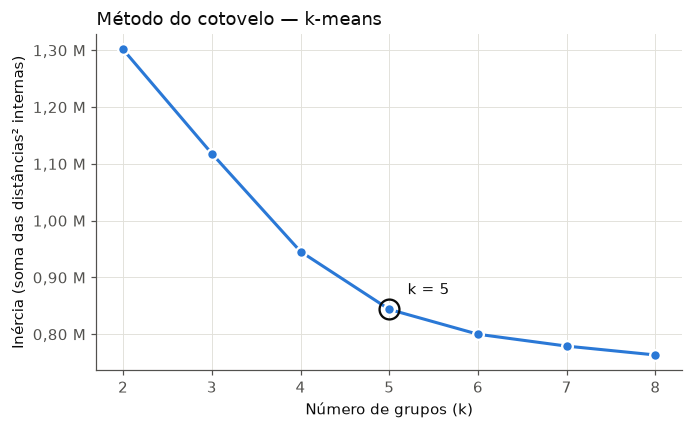

In [11]:
def plot_elbow(inertia, k_chosen, name="fig_cotovelo"):
    # Desenha a curva do cotovelo, marca o k escolhido e salva em results/.
    fig, ax = plt.subplots(figsize=(6.4, 4))
    ax.plot(inertia["k"], inertia["inertia"], color=COLOR_SERIES, linewidth=2,
            marker="o", markersize=7, markeredgecolor="white", markeredgewidth=1.5)

    chosen = inertia.loc[inertia["k"] == k_chosen, "inertia"].item()
    ax.plot(k_chosen, chosen, marker="o", markersize=13, markerfacecolor="none",
            markeredgecolor=COLOR_TEXT, markeredgewidth=1.5)
    ax.annotate(f"k = {k_chosen}", (k_chosen, chosen), xytext=(12, 10),
                textcoords="offset points", color=COLOR_TEXT)

    ax.set_xticks(list(inertia["k"]))
    ax.set_xlabel("Número de grupos (k)")
    ax.set_ylabel("Inércia (soma das distâncias² internas)")
    ax.set_title("Método do cotovelo — k-means", loc="left", color=COLOR_TEXT)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1e6:.2f} M".replace(".", ","))
    fig.tight_layout()

    fig.savefig(RESULTS_DIR / f"{name}.png")
    print(f"Figura salva em {RESULTS_DIR / name}.png")
    plt.show()


plot_elbow(inertia, K_CHOSEN)

### 2.5 Resultados do k-means

Tabela com a inércia para cada k, salva em LaTeX em `results/tab_cotovelo.tex` para uso no relatório.

In [12]:
def elbow_table(inertia):
    # Formata a tabela k x inércia, com a queda percentual em relação ao k anterior.
    table = inertia.copy()
    table["drop"] = -table["inertia"].pct_change() * 100
    table["inertia"] = table["inertia"].map(lambda v: f"{v:,.0f}".replace(",", "."))
    table["drop"] = table["drop"].map(lambda v: "--" if pd.isna(v) else f"{v:.1f}%".replace(".", ","))
    return table.rename(columns={"inertia": "Inércia", "drop": "Queda em relação a k-1"})


elbow_tab = elbow_table(inertia)
save_latex(elbow_tab, "tab_cotovelo.tex",
           "Inércia do k-means para cada valor de k.", "tab:cotovelo")
elbow_tab

Tabela salva em results/tab_cotovelo.tex

,k,Inércia,Queda em relação a k-1
0,2,1.301.489,--
1,3,1.118.218,"14,1%"
2,4,945.655,"15,4%"
3,5,843.806,"10,8%"
4,6,800.037,"5,2%"
5,7,779.142,"2,6%"
6,8,763.533,"2,0%"


## 3 - Agrupamento hierárquico e dendrograma

### 3.1 Configuração

Importa as funções de agrupamento hierárquico do SciPy e define o método de ligação (Ward) e as cores dos grupos.

In [13]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage, set_link_color_palette

# Método de ligação: Ward (mesmo critério de variância interna do k-means)
LINKAGE_METHOD = "ward"

# Cores dos grupos (na ordem 1, 2, 3, ...)
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
                  "#008300", "#6250d6", "#e34948"]

### 3.2 Construção da árvore

Calcula a matriz de ligação `Z`: cada linha registra uma união de dois grupos e a distância em que ela aconteceu.

In [14]:
def build_linkage(X, method=LINKAGE_METHOD):
    # Aplica o agrupamento hierárquico aglomerativo com distância euclidiana.
    return linkage(X.to_numpy(), method=method, metric="euclidean")


Z = build_linkage(X)
print(f"Matriz de ligação: {Z.shape[0]} uniões (801 amostras -> 1 grupo)")
print(f"Distância da última união: {Z[-1, 2]:.1f}")

Matriz de ligação: 800 uniões (801 amostras -> 1 grupo)
Distância da última união: 774.1


### 3.3 Corte da árvore em k grupos

Corta a árvore em `K_CHOSEN` grupos (o mesmo k do cotovelo). Os grupos são renumerados da esquerda para a direita, na ordem em que aparecem no dendrograma.

In [15]:
def cut_tree(Z, k, index):
    # Corta a árvore em k grupos e retorna (grupos por amostra, altura do corte).
    # A altura do corte fica entre a união que forma k grupos e a seguinte.
    heights = Z[:, 2]
    cut_height = (heights[-k] + heights[-(k - 1)]) / 2

    raw = fcluster(Z, k, criterion="maxclust")
    # Renumera os grupos pela ordem das folhas no dendrograma (esquerda -> direita)
    leaves = dendrogram(Z, no_plot=True)["leaves"]
    order = pd.unique(raw[leaves])
    mapping = {old: new for new, old in enumerate(order, start=1)}
    clusters = pd.Series([mapping[c] for c in raw], index=index, name="cluster")
    return clusters, cut_height


hier_clusters, cut_height = cut_tree(Z, K_CHOSEN, X.index)
print(f"Altura do corte para k = {K_CHOSEN}: {cut_height:.1f}")
print("Amostras por grupo:")
print(hier_clusters.value_counts().sort_index().to_string())

Altura do corte para k = 5: 372.3


Amostras por grupo:
cluster
1    146
2    136
3    302
4     78
5    139


### 3.4 Dendrograma

Desenha a árvore completa (801 folhas, sem nomes), colore os ramos abaixo do corte por grupo, marca a linha de corte e indica o grupo e o tamanho sob cada ramo. Salva em `results/fig_dendrograma.png`.

Figura salva em results/fig_dendrograma.png


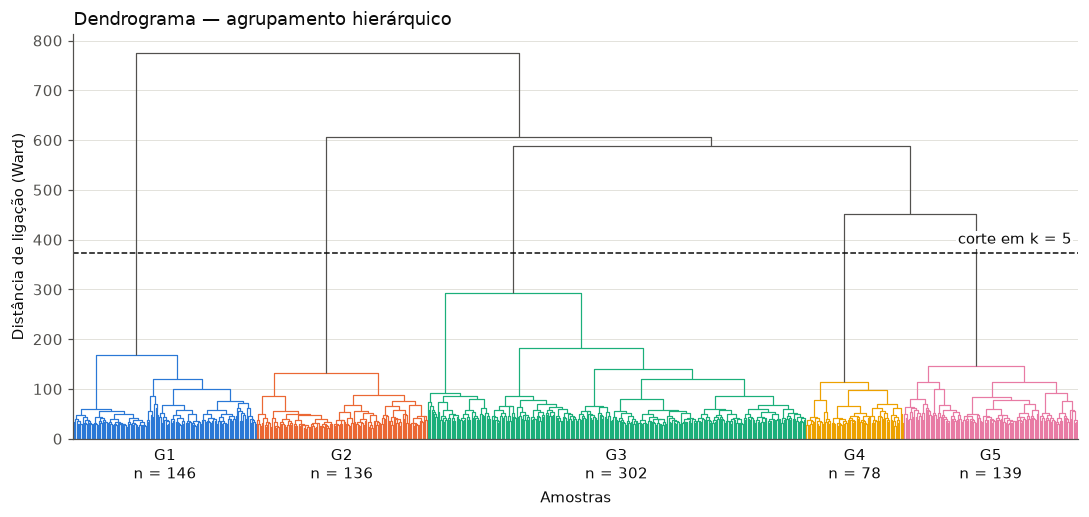

In [16]:
def plot_dendrogram(Z, clusters, cut_height, name="fig_dendrograma"):
    # Desenha o dendrograma colorido pelos grupos do corte e salva em results/.
    k = clusters.nunique()
    set_link_color_palette(CLUSTER_COLORS[:k])
    with plt.rc_context({"lines.linewidth": 0.8}):
        fig, ax = plt.subplots(figsize=(10, 4.8))
        tree = dendrogram(Z, ax=ax, no_labels=True, color_threshold=cut_height,
                          above_threshold_color=COLOR_MUTED)
    set_link_color_palette(None)

    # Linha de corte
    ax.axhline(cut_height, color=COLOR_TEXT, linestyle="--", linewidth=1)
    ax.annotate(f"corte em k = {k}", (1, cut_height), xycoords=("axes fraction", "data"),
                xytext=(-4, 4), textcoords="offset points", ha="right", va="bottom",
                color=COLOR_TEXT, bbox=dict(facecolor="white", edgecolor="none", pad=1))

    # Rótulo de cada grupo sob o seu ramo (folha i fica em x = 5 + 10 i)
    leaf_clusters = clusters.iloc[tree["leaves"]].to_numpy()
    leaf_x = 5 + 10 * np.arange(len(leaf_clusters))
    for c in range(1, k + 1):
        xs = leaf_x[leaf_clusters == c]
        ax.text(xs.mean(), -0.02, f"G{c}\nn = {len(xs)}", transform=ax.get_xaxis_transform(),
                ha="center", va="top", color=COLOR_TEXT)

    ax.grid(axis="x", visible=False)
    ax.set_xlabel("Amostras", labelpad=34)
    ax.set_ylabel("Distância de ligação (Ward)")
    ax.set_title("Dendrograma — agrupamento hierárquico", loc="left", color=COLOR_TEXT)
    fig.tight_layout()

    fig.savefig(RESULTS_DIR / f"{name}.png")
    print(f"Figura salva em {RESULTS_DIR / name}.png")
    plt.show()


plot_dendrogram(Z, hier_clusters, cut_height)

### 3.5 Resultados do agrupamento hierárquico

Tabela com o número de amostras em cada grupo do corte, salva em LaTeX em `results/tab_hierarquico.tex` para uso no relatório.

In [17]:
def cluster_size_table(clusters):
    # Conta as amostras de cada grupo e a porcentagem do total.
    counts = clusters.value_counts().sort_index()
    return pd.DataFrame({
        "Grupo": [f"G{c}" for c in counts.index],
        "Amostras": counts.to_numpy(),
        "Porcentagem": (counts / counts.sum() * 100).map(lambda v: f"{v:.1f}%".replace(".", ",")).to_numpy(),
    })


hier_tab = cluster_size_table(hier_clusters)
save_latex(hier_tab, "tab_hierarquico.tex",
           f"Tamanho dos grupos do agrupamento hierárquico (Ward) cortado em k = {K_CHOSEN}.",
           "tab:hierarquico")
hier_tab

Tabela salva em results/tab_hierarquico.tex


,Grupo,Amostras,Porcentagem
0,G1,146,"18,2%"
1,G2,136,"17,0%"
2,G3,302,"37,7%"
3,G4,78,"9,7%"
4,G5,139,"17,4%"


## 4 - Comparação dos grupos com os tipos de tumor

### 4.1 Tipos de tumor

A partir daqui os rótulos guardados em `labels` passam a ser usados. Mostra quantas amostras há de cada tipo de tumor.

In [18]:
# Ordem fixa das colunas nas tabelas
TUMOR_TYPES = sorted(labels.unique())

labels.value_counts().reindex(TUMOR_TYPES).rename("Amostras").rename_axis("Tipo").to_frame()

,Amostras
Tipo,
BRCA,300
COAD,78
KIRC,146
LUAD,141
PRAD,136


### 4.2 Tabelas de contingência

Monta, para o k-means e para o hierárquico, a tabela com os grupos nas linhas e os tipos de tumor nas colunas, contando as amostras de cada cruzamento (com totais na última linha e coluna).

In [19]:
def contingency_table(clusters, labels, tumor_types=TUMOR_TYPES):
    # Cruza grupos x tipos de tumor e acrescenta os totais.
    table = pd.crosstab(clusters.map(lambda c: f"G{c}"), labels, margins=True, margins_name="Total")
    table = table.reindex(columns=[*tumor_types, "Total"])
    table.index.name = "Grupo"
    table.columns.name = None
    return table


kmeans_contingency = contingency_table(kmeans_clusters, labels)
hier_contingency = contingency_table(hier_clusters, labels)

print("k-means")
display(kmeans_contingency)
print("Hierárquico (Ward)")
display(hier_contingency)

k-means


,BRCA,COAD,KIRC,LUAD,PRAD,Total
Grupo,,,,,,
G1,300,0,1,2,0,303
G2,0,0,145,0,0,145
G3,0,0,0,0,136,136
G4,0,1,0,139,0,140
G5,0,77,0,0,0,77
Total,300,78,146,141,136,801


Hierárquico (Ward)


,BRCA,COAD,KIRC,LUAD,PRAD,Total
Grupo,,,,,,
G1,0,0,146,0,0,146
G2,0,0,0,0,136,136
G3,300,0,0,2,0,302
G4,0,78,0,0,0,78
G5,0,0,0,139,0,139
Total,300,78,146,141,136,801


### 4.3 Tipo majoritário de cada grupo

Para cada grupo, indica o tipo de tumor mais frequente e a fração do grupo que ele representa, nos dois métodos.

In [20]:
def majority_summary(contingency):
    # Retorna, para cada grupo, o tipo majoritário, quantas amostras são dele e a porcentagem do grupo.
    counts = contingency.drop(index="Total", columns="Total")
    majority = counts.idxmax(axis=1)
    n_majority = counts.max(axis=1)
    return pd.DataFrame({
        "Tipo majoritário": majority,
        "Amostras do tipo": n_majority,
        "Amostras no grupo": counts.sum(axis=1),
        "Porcentagem": (n_majority / counts.sum(axis=1) * 100).map(lambda v: f"{v:.1f}%".replace(".", ",")),
    })


print("k-means")
display(majority_summary(kmeans_contingency))
print("Hierárquico (Ward)")
display(majority_summary(hier_contingency))

k-means


,Tipo majoritário,Amostras do tipo,Amostras no grupo,Porcentagem
Grupo,,,,
G1,BRCA,300,303,"99,0%"
G2,KIRC,145,145,"100,0%"
G3,PRAD,136,136,"100,0%"
G4,LUAD,139,140,"99,3%"
G5,COAD,77,77,"100,0%"


Hierárquico (Ward)


,Tipo majoritário,Amostras do tipo,Amostras no grupo,Porcentagem
Grupo,,,,
G1,KIRC,146,146,"100,0%"
G2,PRAD,136,136,"100,0%"
G3,BRCA,300,302,"99,3%"
G4,COAD,78,78,"100,0%"
G5,LUAD,139,139,"100,0%"


### 4.4 Resultados da comparação

Salva as duas tabelas de contingência em LaTeX em `results/tab_contingencia_kmeans.tex` e `results/tab_contingencia_hierarquico.tex` para uso no relatório.

In [21]:
save_latex(kmeans_contingency.reset_index(), "tab_contingencia_kmeans.tex",
           f"Grupos do k-means (k = {K_CHOSEN}) versus tipos de tumor.",
           "tab:contingencia_kmeans")
save_latex(hier_contingency.reset_index(), "tab_contingencia_hierarquico.tex",
           f"Grupos do agrupamento hierárquico (Ward, k = {K_CHOSEN}) versus tipos de tumor.",
           "tab:contingencia_hierarquico")

Tabela salva em results/tab_contingencia_kmeans.tex
Tabela salva em results/tab_contingencia_hierarquico.tex


## 5 - Grupos no gráfico PC1 × PC2 da PCA

### 5.1 Configuração

Importa a PCA do scikit-learn e define os marcadores de cada grupo (usados junto com a cor, para os grupos não dependerem só da cor).

In [22]:
from sklearn.decomposition import PCA

# Marcadores dos grupos (na ordem 1, 2, 3, ...)
CLUSTER_MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]

### 5.2 Aplicação da PCA

Projeta a matriz padronizada `X` nos dois primeiros componentes principais e guarda a fração da variância explicada por cada um.

In [23]:
def run_pca(X, n_components=2, seed=SEED):
    # Retorna (coordenadas PC1/PC2 por amostra, fração da variância explicada por componente).
    pca = PCA(n_components=n_components, random_state=seed)
    scores = pca.fit_transform(X)
    columns = [f"PC{i}" for i in range(1, n_components + 1)]
    scores = pd.DataFrame(scores, index=X.index, columns=columns)
    explained = pd.Series(pca.explained_variance_ratio_, index=columns)
    return scores, explained


pca_scores, pca_explained = run_pca(X)
for pc, ratio in pca_explained.items():
    print(f"{pc}: {ratio * 100:.1f}% da variância")
print(f"Total: {pca_explained.sum() * 100:.1f}%")

PC1: 20.3% da variância
PC2: 11.8% da variância
Total: 32.0%


### 5.3 Gráfico PC1 × PC2

Desenha as amostras no plano PC1 × PC2, uma figura para cada método, coloridas pelo grupo encontrado. A legenda indica o tipo majoritário de cada grupo (passo 4), e as amostras cujo tipo real é diferente do majoritário do grupo são circuladas. Salva em `results/fig_pca_grupos.png`.

Figura salva em results/fig_pca_grupos.png


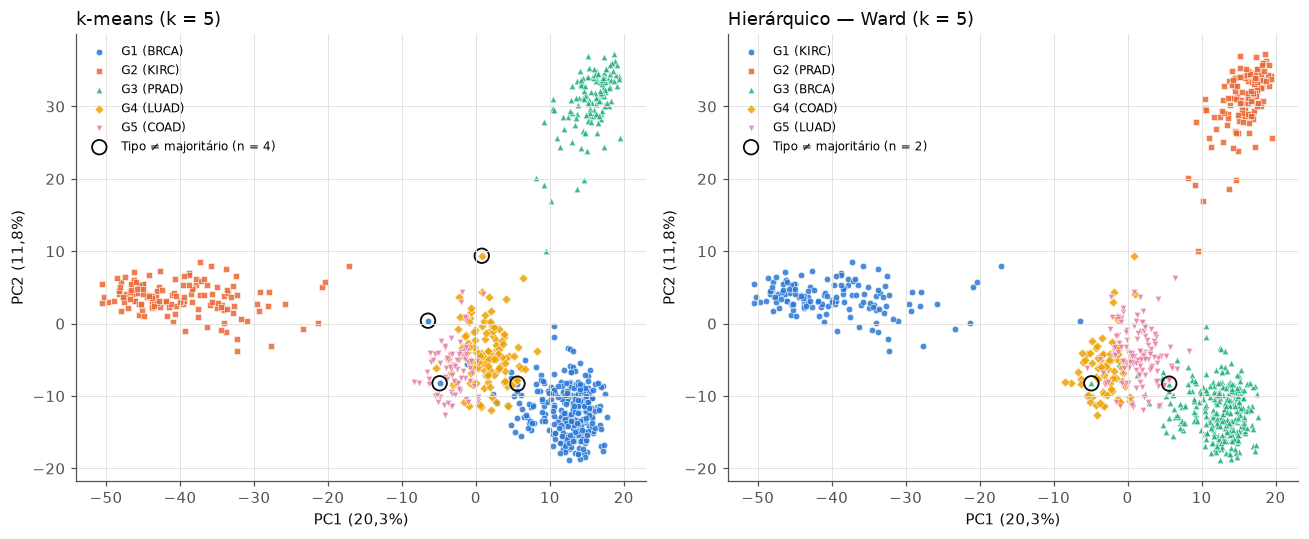

In [24]:
def plot_pca_clusters(ax, scores, explained, clusters, contingency, title):
    # Desenha as amostras de cada grupo e destaca as que não são do tipo majoritário.
    majority = majority_summary(contingency)["Tipo majoritário"]

    for c in sorted(clusters.unique()):
        points = scores[clusters == c]
        ax.scatter(points["PC1"], points["PC2"], s=18, color=CLUSTER_COLORS[c - 1],
                   marker=CLUSTER_MARKERS[c - 1], edgecolors="white", linewidths=0.4,
                   alpha=0.85, label=f"G{c} ({majority[f'G{c}']})")

    # Amostras cujo tipo real difere do majoritário do grupo
    mismatch = labels != clusters.map(lambda c: majority[f"G{c}"])
    ax.scatter(scores.loc[mismatch, "PC1"], scores.loc[mismatch, "PC2"], s=90,
               facecolors="none", edgecolors=COLOR_TEXT, linewidths=1.2,
               label=f"Tipo ≠ majoritário (n = {mismatch.sum()})")

    ax.set_xlabel(f"PC1 ({explained['PC1'] * 100:.1f}%)".replace(".", ","))
    ax.set_ylabel(f"PC2 ({explained['PC2'] * 100:.1f}%)".replace(".", ","))
    ax.set_title(title, loc="left", color=COLOR_TEXT)
    ax.legend(frameon=False, fontsize=8, loc="best")


def plot_pca_figure(scores, explained, name="fig_pca_grupos"):
    # Monta a figura com os dois métodos lado a lado e salva em results/.
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
    plot_pca_clusters(axes[0], scores, explained, kmeans_clusters, kmeans_contingency,
                      f"k-means (k = {K_CHOSEN})")
    plot_pca_clusters(axes[1], scores, explained, hier_clusters, hier_contingency,
                      f"Hierárquico — Ward (k = {K_CHOSEN})")
    axes[1].tick_params(labelleft=True)
    fig.tight_layout()

    fig.savefig(RESULTS_DIR / f"{name}.png")
    print(f"Figura salva em {RESULTS_DIR / name}.png")
    plt.show()


plot_pca_figure(pca_scores, pca_explained)

### 5.4 Resultados da PCA

Tabela com a variância explicada por PC1 e PC2, salva em LaTeX em `results/tab_pca.tex` para uso no relatório.

In [25]:
def pca_table(explained):
    # Formata a variância explicada por componente e a acumulada.
    to_pct = lambda v: f"{v * 100:.1f}%".replace(".", ",")
    return pd.DataFrame({
        "Componente": explained.index,
        "Variância explicada": explained.map(to_pct).to_numpy(),
        "Acumulada": explained.cumsum().map(to_pct).to_numpy(),
    })


pca_tab = pca_table(pca_explained)
save_latex(pca_tab, "tab_pca.tex",
           "Variância explicada pelos dois primeiros componentes principais.", "tab:pca")
pca_tab

Tabela salva em results/tab_pca.tex


,Componente,Variância explicada,Acumulada
0,PC1,"20,3%","20,3%"
1,PC2,"11,8%","32,0%"


## 6 - Respostas às perguntas

**O método do cotovelo apontou k = 5, que é o número real de tipos?**

Sim. O critério da seção 2.3 (ponto mais distante da reta entre o primeiro e o último ponto da curva) escolheu k = 5, e o gráfico da seção 2.4 confirma: a inércia cai 15,4% de k = 3 para 4 e 10,8% de 4 para 5, mas só 5,2% de 5 para 6 e cerca de 2% nos passos seguintes. Ainda assim, a curva é suave e o cotovelo não é um ponto muito marcado; sem o critério automático, k = 4 ou 6 também poderiam ser defendidos olhando só o gráfico.

**Algum tipo de tumor ficou dividido em dois grupos, ou dois tipos caíram no mesmo grupo?**

Não. Nas tabelas da seção 4.2, cada grupo tem pelo menos 99% das amostras de um único tipo, e cada tipo está concentrado em um único grupo. As exceções são poucas amostras isoladas:

- **k-means:** 4 de 801 amostras (1 KIRC e 2 LUAD no grupo de BRCA; 1 COAD no grupo de LUAD);
- **hierárquico (Ward):** 2 de 801 amostras (2 LUAD no grupo de BRCA).

No gráfico da PCA (seção 5.3), LUAD e COAD se sobrepõem no plano PC1 × PC2, mas os dois métodos os separaram mesmo assim, porque agrupam usando os 2.000 genes, e não só os dois componentes do gráfico (que explicam 32% da variância).

**Por que um método de agrupamento pode encontrar uma divisão diferente da esperada sem estar errado?**

Porque o agrupamento não busca os tipos de tumor: ele busca a divisão que otimiza um critério geométrico (no k-means e no Ward, a menor variância dentro dos grupos), e essa divisão depende de escolhas feitas antes, como o valor de k, os genes usados, a padronização e o método de ligação. Os rótulos são só uma das divisões biologicamente válidas dos dados. Se houver subtipos moleculares dentro de um tumor, ou tumores de tecidos diferentes com perfis de expressão parecidos, o método pode dividir um tipo ou juntar dois, e esse resultado também descreve uma estrutura real dos dados.

O próprio dendrograma (seção 3.4) mostra isso: o ramo de BRCA se divide em dois logo abaixo do corte (distância de ~290), então com k = 6 o BRCA ficaria separado em dois grupos; e COAD e LUAD são os primeiros a se unir acima do corte (~450), então com k = 4 eles cairiam no mesmo grupo. Nenhuma dessas divisões estaria errada: elas apenas mostram a estrutura dos dados em outra escala.